ACO Best Distance: 388.2


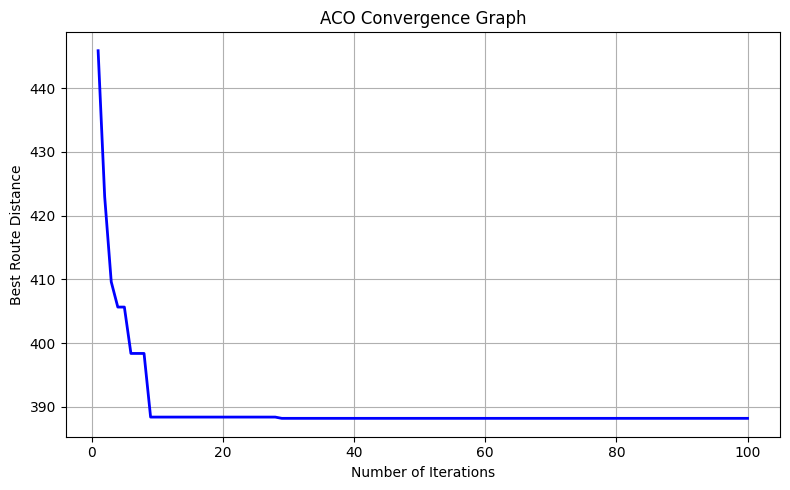

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# ANT COLONY OPTIMIZATION (ACO) FOR TSP
# ==========================================

np.random.seed(42)

n_cities = 20
n_ants = 30
iterations = 100

# Generate random city coordinates in a 100x100 grid
cities = np.random.rand(n_cities, 2) * 100

# Calculate Euclidean distance matrix
distance = np.zeros((n_cities, n_cities))
for i in range(n_cities):
    for j in range(n_cities):
        distance[i, j] = np.linalg.norm(cities[i] - cities[j])

def route_length(route):
    """Computes total distance of a given route loop."""
    total = 0
    for i in range(len(route)):
        total += distance[route[i], route[(i + 1) % len(route)]]
    return total

def run_aco():
    alpha = 1.0    # Pheromone importance weight
    beta = 5.0     # Heuristic importance weight
    evaporation = 0.5
    Q = 100.0

    pheromone = np.ones((n_cities, n_cities))
    best_route = None
    best_distance = float("inf")
    convergence = []

    for _ in range(iterations):
        all_routes = []
        all_distances = []

        for _ in range(n_ants):
            start = np.random.randint(n_cities)
            route = [start]
            unvisited = list(range(n_cities))
            unvisited.remove(start)

            while unvisited:
                current = route[-1]
                probabilities = []

                for city in unvisited:
                    tau = pheromone[current][city] ** alpha
                    eta = (1.0 / (distance[current][city] + 1e-10)) ** beta
                    probabilities.append(tau * eta)

                probabilities = np.array(probabilities)
                probabilities /= probabilities.sum()

                next_city = np.random.choice(unvisited, p=probabilities)
                route.append(next_city)
                unvisited.remove(next_city)

            d = route_length(route)
            all_routes.append(route)
            all_distances.append(d)

            if d < best_distance:
                best_distance = d
                best_route = route.copy()

        # Pheromone evaporation
        pheromone *= (1.0 - evaporation)

        # Pheromone deposit based on solution quality
        for route, d in zip(all_routes, all_distances):
            for i in range(n_cities):
                a = route[i]
                b = route[(i + 1) % n_cities]
                pheromone[a][b] += Q / d
                pheromone[b][a] += Q / d

        convergence.append(best_distance)

    return best_route, best_distance, convergence

# Run and Plot ACO
aco_route, aco_dist, aco_curve = run_aco()
print(f"ACO Best Distance: {round(aco_dist, 2)}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), aco_curve, color="blue", linewidth=2)
plt.title("ACO Convergence Graph")
plt.xlabel("Number of Iterations")
plt.ylabel("Best Route Distance")
plt.grid(True)
plt.tight_layout()
plt.show()